# 3 – Model Comparison: six model families

Every model uses the same prepared data (notebook 1), is tuned with the same **GridSearchCV + stratified 5-fold cross-validation** on the training set (scoring = **macro F1**), and is tested once on the same **885 unseen students**.

| Model family | How it decides | Hyperparameters tuned |
|---|---|---|
| Logistic Regression | weighted sum of the features → softmax probabilities | `C`, `class_weight` |
| Random Forest | majority vote of many decision trees, each trained on a bootstrap sample | `max_depth`, `min_samples_leaf`, `class_weight` |
| Support Vector Machine | the boundary with the widest margin (straight with a linear kernel, curved with RBF) | `kernel`, `C`, `class_weight` |
| K-Nearest Neighbours | vote of the k most similar training students | `n_neighbors`, `weights`, `metric` |
| Neural network (MLP) | layers of neurons with ReLU, trained by backpropagation | hidden layers, `alpha` (L2 penalty) |
| K-Means (unsupervised) | groups students by similarity without seeing the labels | `k` (elbow method + silhouette) |

## 1. Import libraries

In [1]:
import joblib
from math import prod
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, silhouette_score,
                             confusion_matrix, ConfusionMatrixDisplay)

## 2. Load the prepared data

In [2]:
train = pd.read_csv("data/processed/train.csv")
test = pd.read_csv("data/processed/test.csv")

X_train, y_train = train.drop(columns="target"), train["target"]
X_test, y_test = test.drop(columns="target"), test["target"]
classes = ["Dropout", "Enrolled", "Graduate"]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (3539, 110) | Test: (885, 110)


## 3. The five classifiers and their search grids
- Random Forest depth is limited (6–14) to reduce overfitting and keep the trees small enough for the web demo.
- The MLP uses `early_stopping=True`: it keeps 10% of the training data aside and stops when the validation score stops improving.

In [3]:
weights_15 = {"Dropout": 1, "Enrolled": 1.5, "Graduate": 1}
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42),
                            {"C": [0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced", weights_15]}),
    "Random Forest": (RandomForestClassifier(n_estimators=150, random_state=42),
                      {"max_depth": [6, 10, 14], "min_samples_leaf": [2, 5, 10], "class_weight": [None, "balanced"]}),
    "SVM": (SVC(random_state=42),
            {"kernel": ["linear", "rbf"], "C": [0.1, 1, 10], "class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(),
            {"n_neighbors": [5, 11, 21, 31], "weights": ["uniform", "distance"], "metric": ["euclidean", "manhattan"]}),
    "Neural Network (MLP)": (MLPClassifier(max_iter=500, early_stopping=True, random_state=42),
                             {"hidden_layer_sizes": [(32,), (64,), (64, 32)], "alpha": [0.0001, 0.001, 0.01]}),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Settings to try:", sum(prod(len(v) for v in grid.values()) for _, grid in models.values()))

Settings to try: 70


## 4. Tune every model, then test it once
For each family: GridSearchCV finds the best setting on the training data, then the best model is scored on the test set. (Takes a few minutes.)

In [4]:
rows, best_models = [], {}
for name, (model, grid) in models.items():
    search = GridSearchCV(model, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    pred = best.predict(X_test)
    auc = roc_auc_score(y_test, best.predict_proba(X_test), multi_class="ovr") if hasattr(best, "predict_proba") else None
    rows.append({"Model": name, "Best settings": search.best_params_, "CV macro F1": search.best_score_,
                 "Test accuracy": accuracy_score(y_test, pred), "Test macro F1": f1_score(y_test, pred, average="macro"),
                 "ROC AUC": auc, "Train-test gap": f1_score(y_train, best.predict(X_train), average="macro") - f1_score(y_test, pred, average="macro")})
    best_models[name] = best
    print(f"{name:22s} CV F1 {search.best_score_:.4f} | test F1 {rows[-1]['Test macro F1']:.4f} | {search.best_params_}")

Logistic Regression    CV F1 0.7174 | test F1 0.7067 | {'C': 0.1, 'class_weight': {'Dropout': 1, 'Enrolled': 1.5, 'Graduate': 1}}
Random Forest          CV F1 0.7200 | test F1 0.7088 | {'class_weight': 'balanced', 'max_depth': 14, 'min_samples_leaf': 2}
SVM                    CV F1 0.7189 | test F1 0.6890 | {'C': 1, 'class_weight': 'balanced', 'kernel': 'rbf'}
KNN                    CV F1 0.6550 | test F1 0.6381 | {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Neural Network (MLP)   CV F1 0.6988 | test F1 0.7075 | {'alpha': 0.01, 'hidden_layer_sizes': (64, 32)}


## 5. Comparison table

In [5]:
results = pd.DataFrame(rows).set_index("Model").sort_values("Test macro F1", ascending=False)
results.to_csv("results/model_comparison.csv")
results.drop(columns="Best settings").round(3)

,CV macro F1,Test accuracy,Test macro F1,ROC AUC,Train-test gap
Model,,,,,
Random Forest,0.720,0.751,0.709,0.890,0.200
Neural Network (MLP),0.699,0.768,0.707,0.875,0.099
Logistic Regression,0.717,0.763,0.707,0.888,0.039
SVM,0.719,0.729,0.689,NaN,0.124
KNN,0.655,0.731,0.638,0.827,0.362


## 6. Test macro F1 of each model

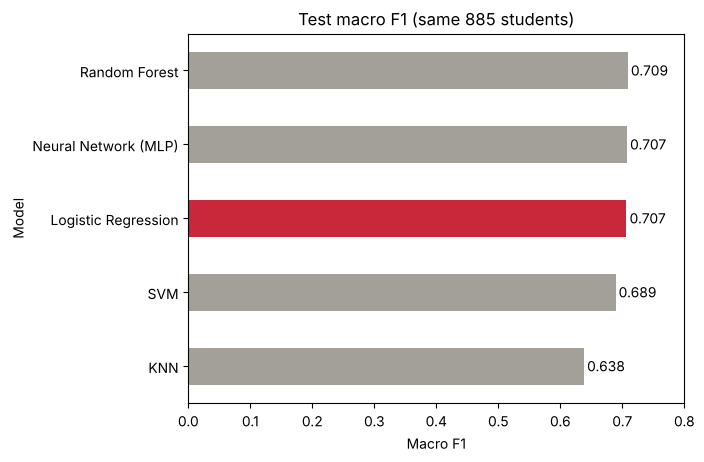

In [6]:
scores = results["Test macro F1"].sort_values()
colors = ["#c8283a" if m == "Logistic Regression" else "#a3a09a" for m in scores.index]
scores.plot(kind="barh", color=colors, xlim=(0, 0.8))
for i, v in enumerate(scores):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.title("Test macro F1 (same 885 students)")
plt.xlabel("Macro F1")
plt.show()

## 7. Where do the models make mistakes? F1 for each class

In [7]:
per_class = pd.DataFrame({name: f1_score(y_test, m.predict(X_test), average=None, labels=classes)
                          for name, m in best_models.items()}, index=classes).T
per_class.round(3)

,Dropout,Enrolled,Graduate
Logistic Regression,0.752,0.506,0.862
Random Forest,0.771,0.515,0.841
SVM,0.740,0.503,0.825
KNN,0.728,0.358,0.829
Neural Network (MLP),0.761,0.498,0.863


## 8. Confusion matrix of the best-scoring model

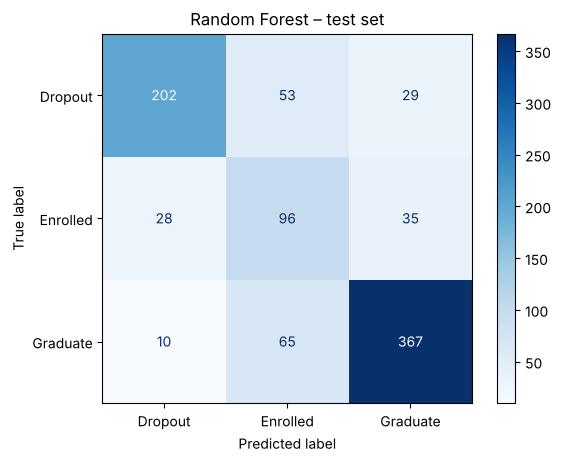

In [8]:
top = results.index[0]
ConfusionMatrixDisplay(confusion_matrix(y_test, best_models[top].predict(X_test), labels=classes),
                       display_labels=classes).plot(cmap="Blues")
plt.title(f"{top} – test set")
plt.show()

## 9. K-Means clustering (unsupervised)
K-Means never sees the outcome. The **elbow method** (inertia) and the **silhouette score** help to choose k; afterwards I compare the clusters with the real outcomes.

{2: 0.271, 3: 0.285, 4: 0.183, 5: 0.133, 6: 0.087, 7: 0.107, 8: 0.096}


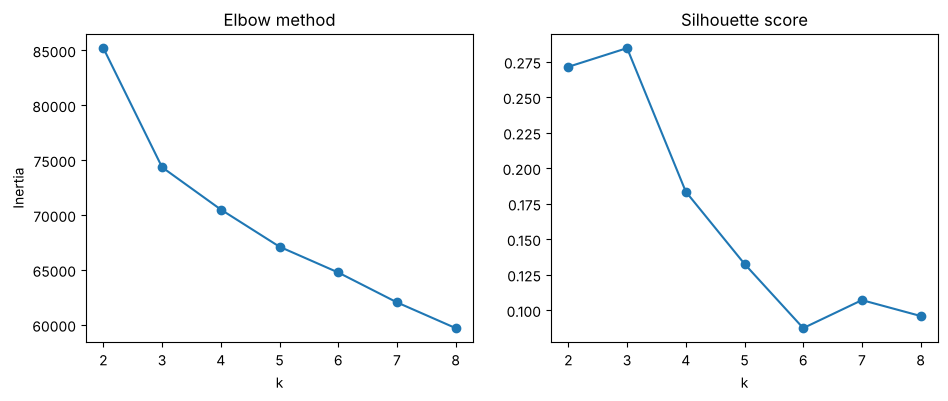

In [9]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_train)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_train, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(ks, silhouette, marker="o"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.show()
print({k: round(s, 3) for k, s in zip(ks, silhouette)})

In [10]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_train)
print("Silhouette (k = 3):", round(silhouette_score(X_train, kmeans.labels_), 3))
pd.crosstab(kmeans.labels_, y_train, normalize="index").round(2)

Silhouette (k = 3): 0.285


target,Dropout,Enrolled,Graduate
row_0,,,
0,0.18,0.21,0.61
1,0.82,0.09,0.08
2,0.25,0.15,0.60


What do the students in each cluster look like? (scaled values: 0 = average, below 0 = below average)

In [11]:
profile = ["num__approval_rate_2nd", "num__Curricular units 2nd sem (grade)", "num__failed_units"]
X_train.groupby(kmeans.labels_)[profile].mean().round(2)

,num__approval_rate_2nd,num__Curricular units 2nd sem (grade),num__failed_units
0,0.45,0.49,-0.38
1,-1.66,-1.78,1.28
2,0.53,0.48,-0.03


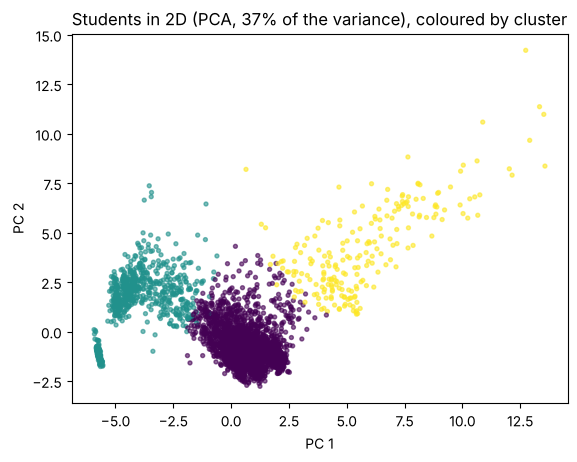

In [12]:
pca = PCA(n_components=2).fit(X_train)
points = pca.transform(X_train)
plt.scatter(points[:, 0], points[:, 1], c=kmeans.labels_, s=8, cmap="viridis", alpha=0.6)
plt.title(f"Students in 2D (PCA, {pca.explained_variance_ratio_.sum():.0%} of the variance), coloured by cluster")
plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.show()

## 10. Save the models for the web demo

In [13]:
files = {"Logistic Regression": "logreg", "Random Forest": "random_forest", "SVM": "svm",
         "KNN": "knn", "Neural Network (MLP)": "mlp"}
for name, model in best_models.items():
    joblib.dump(model, f"models/{files[name]}.joblib")
joblib.dump(kmeans, "models/kmeans.joblib")
print("Saved:", sorted(files.values()) + ["kmeans"])

Saved: ['knn', 'logreg', 'mlp', 'random_forest', 'svm', 'kmeans']


## Conclusion
- **Models trained:** 5 classifiers with 70 settings in total (350 cross-validation fits), plus K-Means for k = 2 to 8.
- **The top three are tied:** Random Forest (0.709), the neural network (0.707) and Logistic Regression (0.707) finish within 0.002 macro F1. On 885 test students a difference this small does not make one of them better.
- **Overfitting decides:** the train–test gap is 0.039 for Logistic Regression, 0.099 for the MLP and 0.200 for Random Forest (training F1 0.909). The best Random Forest depth (14) and leaf size (2) are at the edge of the grid; I kept the depth limited so the trees stay small enough for the web demo.
- **Main model = Logistic Regression:** the same macro F1 as the best model, the smallest gap, ROC-AUC 0.888, and weights that can be explained to university staff.
- **SVM and KNN:** the SVM scored well in cross-validation (0.719) but lower on the test set (0.689). KNN was the weakest (0.638). With distance weights each training student is its own nearest neighbour, so its training F1 is 1.0 (gap 0.362), and distances over 110 mostly one-hot features are less meaningful.
- **Hardest class:** Enrolled is the hardest class for every model (F1 0.36–0.51); Graduate is the easiest (0.82–0.86).
- **K-Means:** k = 3 has the best silhouette score (0.285, a weak but real structure). Without seeing the labels, it found a cluster of 766 students that is 82% Dropout: students with low approval rates, low grades and more failed units.
- **Limitations and improvements:** the data come from one institution. Next I would try a wider Random Forest grid, gradient boosting, and SVM probabilities (`probability=True`).